In [1]:
pip -q install langgraph langchain langchain-core langchain-groq groq

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import getpass

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Digite sua GROQ_API_KEY: ")
print("✅ GROQ_API_KEY configurada!")

✅ GROQ_API_KEY configurada!


In [2]:
import os
import re
from getpass import getpass

from typing_extensions import TypedDict
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

In [3]:
def make_llm(temperature: float = 0.7) -> ChatGroq:
    return ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=temperature,
    )

llm = make_llm()
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000239E75EA840>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000239E7858740>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

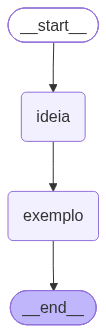

In [5]:
class TravelState(TypedDict, total=False):
    ideia: str
    exemplo: str

def node_ideia(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content="Gere uma ideia de exemplo prático (1 frase) para ensinar conceitos moeda quântica.")
    ])
    return {"ideia": resp.content.strip()}

def node_exemplo(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content=(
            "Crie um exemplo prático de sala de aula usando a ideia abaixo.\n"
            f"IDEIA: {state.get('ideia','')}\n"
            "Formato: 6-10 linhas, com bullets."
        ))
    ])
    return {"exemplo": resp.content}

travel_builder = StateGraph(TravelState)
travel_builder.add_node("ideia", node_ideia)
travel_builder.add_node("exemplo", node_exemplo)
travel_builder.add_edge(START, "ideia")
travel_builder.add_edge("ideia", "exemplo")
travel_builder.add_edge("exemplo", END)

travel_checkpointer = MemorySaver()
travel_graph = travel_builder.compile(checkpointer=travel_checkpointer)
travel_graph



In [6]:
t_cfg = {"configurable": {"thread_id": "travel-01"}}

original = travel_graph.invoke({}, config=t_cfg)

print("IDEIA:", original["ideia"])
print("EXEMPLO:\n", original["exemplo"])

IDEIA: "Imagine que duas pessoas lançam uma moeda virtual que, ao ser medida, pode aparecer simultaneamente como cara e coroa até que cada uma observe seu resultado, ilustrando superposição e colapso da moeda quântica."
EXEMPLO:
 - **Objetivo:** Demonstrar superposição e colapso de estado usando uma moeda quântica virtual.  
- **Material:** Aplicativo ou página web que gera “moeda quântica” (estado |cara⟩ + |coroa⟩).  
- **Divisão:** Forme duplas; cada aluno recebe um avatar que “lança” a moeda simultaneamente.  
- **Etapa 1 – Superposição:** Antes de observar, a tela mostra a moeda girando com as duas faces sobrepostas (ícone transparente de cara e coroa).  
- **Etapa 2 – Medição individual:** Cada aluno clica em “observar”. O aplicativo colapsa o estado apenas para aquele avatar, revelando cara ou coroa aleatoriamente.  
- **Etapa 3 – Comparação:** Os parceiros revelam seus resultados; podem ser iguais ou diferentes, ilustrando que a medição local determina o estado.  
- **Discussão:

In [9]:
history = list(travel_graph.get_state_history(t_cfg))
print("Quantidade de checkpoints:", len(history))

for i, st in enumerate(history[:6]):
    checkpoint_id = st.config["configurable"].get("checkpoint_id")
    print(f"{i}: next={st.next} | checkpoint_id={checkpoint_id} | keys={list(st.values.keys())}")

Quantidade de checkpoints: 4
0: next=() | checkpoint_id=1f1d7db0-0594-619b-8002-c473d33d22b6 | keys=['ideia', 'exemplo']
1: next=('exemplo',) | checkpoint_id=1f1d7daf-fb5c-6317-8001-caf87f87bfdf | keys=['ideia']
2: next=('ideia',) | checkpoint_id=1f1d7daf-f4a3-6a9b-8000-711fa6cf4cb7 | keys=[]
3: next=('__start__',) | checkpoint_id=1f1d7daf-f4a3-6a9a-bfff-d84e12dfe0b3 | keys=[]


In [10]:
selected = next(
    st for st in history
    if st.next == ("exemplo",)
)

print("Checkpoint de origem:", selected.config["configurable"]["checkpoint_id"])

# Fork 1: atendimento de dúvidas.
config_fork1 = travel_graph.update_state(
    selected.config,
    values={
        "ideia": "Criar um chatbot que responde dúvidas do aluno sobre Python."
    },
)

fork1 = travel_graph.invoke(None, config=config_fork1)

# Fork 2: quiz adaptativo, partindo do mesmo checkpoint.
config_fork2 = travel_graph.update_state(
    selected.config,
    values={
        "ideia": "Criar um quiz que ajusta a dificuldade conforme os acertos do aluno."
    },
)

fork2 = travel_graph.invoke(None, config=config_fork2)



print("\n--- FORK 1 ---")
print("IDEIA:", fork1["ideia"])
print("EXEMPLO:\n", fork1["exemplo"])

print("\n--- FORK 2 ---")
print("IDEIA:", fork2["ideia"])
print("EXEMPLO:\n", fork2["exemplo"])

print("\n--- COMPARAÇÃO ---")
print("As ideias são iguais?", fork1["ideia"] == fork2["ideia"])
print("Os exemplos são iguais?", fork1["exemplo"] == fork2["exemplo"])

Checkpoint de origem: 1f1d7daf-fb5c-6317-8001-caf87f87bfdf

--- FORK 1 ---
IDEIA: Criar um chatbot que responde dúvidas do aluno sobre Python.
EXEMPLO:
 - **Objetivo:** Introduzir um chatbot de IA que responde dúvidas sobre sintaxe e conceitos básicos de Python.  
- **Ferramentas:** Python, API do OpenAI (ou modelo local), Flask para criar a interface web.  
- **Atividade 1:** Cada aluno cria uma conta no GitHub Classroom e clona o repositório com o código‑base do chatbot.  
- **Atividade 2:** Em duplas, os alunos treinam o bot adicionando perguntas‑respostas típicas (ex.: “Como faço um loop for?”).  
- **Atividade 3:** Os grupos testam o bot no navegador, enviando dúvidas reais enquanto escrevem pequenos scripts.  
- **Avaliação:** O professor verifica o log de interações; pontua a clareza das respostas e a cobertura de tópicos.  
- **Extensão:** Integrar o bot ao Discord da turma para suporte contínuo fora da aula.

--- FORK 2 ---
IDEIA: Criar um quiz que ajusta a dificuldade conform